# 24 — Time-varying world risk prices across countries

Audit the world instruments **before fitting**, then compare constant and time-varying world
prices for **Poland, Czechia, Romania, Sweden and Hungary**, in **USD and EUR**, under both
**scalar and diagonal BEKK**. Keep **October 2014–September 2026 (144 months)** in every system.

Retain notebook 23's **corrected priced FX means**, zero equity alphas and the same five equity/FX
observations. FX and US/national local prices are jointly re-estimated but remain constant.
Reuse 20 verified constant-world references and estimate 20 conditional-world systems.

Use the existing **Miniconda base** kernel. No fetching, installation, custom kernel, revised
observations or overwriting earlier research outputs. The model engine reuses the verified
`pricing_robustness.py` filter with only the world conditioning design extended.

In [1]:
# Fixed common sample; adjustable numerical and diagnostic controls.
START_DYNAMICS = [(0.05, 0.90), (0.10, 0.70)]
MAX_ITER = 2000
TEST_LAGS = 12
HAC_LAGS = (0, 3, 6, 12)
REUSE_FITS = True
MODEL_VERSION = "regional_time_varying_world_priced_means_v1"
WORLD_INSTRUMENTS = ["short_rate_change_lag1_pp", "term_spread_change_lag1_pp", "credit_spread_lag1_pp"]
PREVIOUS_MANIFEST_SHA = "c7c249686fa53d58211cb04ee8dc551e6071415742975a1e5ccf0c51a8963545"
LOCK_HASHES = {
    "regional_dataset_inputs.json": "0ceeef569dc4513d8534faf346509b22245db7ebff63abeb77044fc1474be208",
    "research_synthesis_inputs.json": "4fc2f36215746dd0ad0fef3ac41d8953f4abc6f1a3a36b526813437a26f081ee",
}

from pathlib import Path
from io import BytesIO
import hashlib, importlib, importlib.metadata, json, os, platform, sys
ROOT = Path.cwd()
os.environ.setdefault("MPLCONFIGDIR", str(ROOT/".cache"/"matplotlib"))
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import norm, chi2
from packaging.version import Version
versions = {p: importlib.metadata.version(p) for p in
            ["numpy", "pandas", "scipy", "statsmodels", "matplotlib", "ipykernel"]}
if Version(versions["statsmodels"]) < Version("0.15.0"):
    raise RuntimeError("Use the base environment already used for notebooks 20–22 (statsmodels 0.15.0 or later).")
if "statsmodels" in sys.modules and sys.modules["statsmodels"].__version__ != versions["statsmodels"]:
    raise RuntimeError("Restart the existing base kernel to discard stale statsmodels imports.")
from statsmodels.stats.diagnostic import acorr_ljungbox, het_arch
from statsmodels.stats.multitest import multipletests
from IPython.display import display, Markdown
import pricing_robustness as core
importlib.reload(core)
import regional_world_pricing as engine
importlib.reload(engine)

NAMES = {"PL": "Poland", "CZ": "Czechia", "RO": "Romania", "SE": "Sweden", "HU": "Hungary"}
LOCAL_CURRENCIES = {"PL": "PLN", "CZ": "CZK", "RO": "RON", "SE": "SEK", "HU": "HUF"}
COUNTRY_ORDER, CURRENCIES, COVARIANCES = ["HU", "PL", "CZ", "RO", "SE"], ["USD", "EUR"], ["scalar", "diagonal"]
ASSETS = ["World", "US", "National", "National FX", "Other FX"]
COLORS = {"PL": "#285f9e", "CZ": "#2a8a70", "RO": "#9469ad", "SE": "#b77d13", "HU": "#c4483b"}
PREVIOUS = ROOT/"output"/"23_regional_currency_risk"/"2014-10_2026-09"
CANDIDATES = ["short_rate_change_lag1_pp", "term_spread_change_lag1_pp", "credit_spread_lag1_pp"]
assert WORLD_INSTRUMENTS and len(set(WORLD_INSTRUMENTS)) == len(WORLD_INSTRUMENTS)
assert all(name in CANDIDATES for name in WORLD_INSTRUMENTS)
instrument_id = hashlib.sha256(json.dumps(WORLD_INSTRUMENTS).encode()).hexdigest()[:8]
OUT = ROOT/"output"/"24_regional_time_varying_world"/"2014-10_2026-09"/f"z_{instrument_id}"
OUT.mkdir(parents=True, exist_ok=True)
def sha(raw): return hashlib.sha256(raw).hexdigest()
engine_hashes = {name: sha((ROOT/name).read_bytes()) for name in
    ["regional_world_pricing.py", "regional_currency_pricing.py", "pricing_robustness.py", "regional_pricing_baseline.py", "regional_covariance_sensitivity.py"]}
assert 2 <= TEST_LAGS <= 24 and tuple(HAC_LAGS) == (0, 3, 6, 12)
assert all(a > 0 and b > 0 and a+b < 1 for a, b in START_DYNAMICS)
plt.rcParams.update({"figure.dpi": 110, "font.size": 10, "axes.spines.top": False,
                     "axes.spines.right": False, "axes.grid": True, "grid.alpha": .18})
pd.set_option("display.max_columns", 14)
print("Python:", sys.executable)
print("Packages:", versions)
import warnings
from statsmodels.tsa.stattools import adfuller, kpss
from statsmodels.stats.outliers_influence import variance_inflation_factor
from statsmodels.tools.sm_exceptions import InterpolationWarning
print("World engine SHA-256:", engine_hashes["regional_world_pricing.py"])

Python: /Users/lajosgalambos/miniconda3/bin/python
Packages: {'numpy': '2.4.4', 'pandas': '3.0.2', 'scipy': '1.17.1', 'statsmodels': '0.15.0', 'matplotlib': '3.10.8', 'ipykernel': '7.2.0'}
World engine SHA-256: a6b3e3108c003fb737dfd5b979bcd425cdfac1057eaf02218ece7dbde204e8f8


## 1. Verify frozen inputs and constant-world references

Verify the pinned notebook-23 manifest and all of its protected inputs, outputs and engine files.
Use its with-FX fits as the constant-world references. Re-filter them on exactly the same observations
and verify saved likelihoods, means, covariances and scores before any comparison. No full-history
Hungarian fit is substituted for the matched Hungarian reference.

In [2]:
def verify_inputs():
    raw = (PREVIOUS/"estimation_manifest.json").read_bytes()
    if sha(raw) != PREVIOUS_MANIFEST_SHA: raise ValueError("Notebook-23 manifest changed.")
    previous = json.loads(raw)
    assert previous["input_locks"] == LOCK_HASHES
    assert (previous["first"], previous["last"], previous["observations_per_fit"]) == ("2014-10", "2026-09", 144)
    expected = previous["input_file_hashes"].copy()
    for name, checksum in previous["outputs"].items():
        expected[(PREVIOUS/name).relative_to(ROOT).as_posix()] = checksum
    expected[(PREVIOUS/"estimation_manifest.json").relative_to(ROOT).as_posix()] = PREVIOUS_MANIFEST_SHA
    expected.update(previous["engines"])
    locks = {}
    for name, checksum in LOCK_HASHES.items():
        content = (ROOT/name).read_bytes()
        if sha(content) != checksum: raise ValueError(f"Changed input lock: {name}")
        locks[name] = json.loads(content)
    for path, checksum in expected.items():
        if sha((ROOT/path).read_bytes()) != checksum: raise ValueError(f"Changed frozen input: {path}")
    regional = locks["regional_dataset_inputs.json"]
    assert sha((ROOT/regional["root"]/"manifest.json").read_bytes()) == regional["manifest_sha256"]
    return locks, expected

locks, input_hashes = verify_inputs()
regional = locks["regional_dataset_inputs.json"]
assert (regional["common_start"], regional["common_end"], regional["common_months"]) == ("2014-10", "2026-09", 144)
months = pd.period_range("2014-10", "2026-09", freq="M", name="month")
frames, samples, scales, source_hashes, audit_rows = {}, {}, {}, {}, []
for country in COUNTRY_ORDER:
    for currency in CURRENCIES:
        path = ROOT/regional["root"]/"common"/f"{country}_{currency}.csv"
        raw = path.read_bytes()
        assert sha(raw) == input_hashes[path.relative_to(ROOT).as_posix()]
        d = pd.read_csv(BytesIO(raw), index_col=0, float_precision="round_trip")
        d.index = pd.PeriodIndex(d.index, freq="M", name="month")
        assert d.index.equals(months) and np.isfinite(d.to_numpy()).all() and d.flag_known_index_backcast.sum() == 0
        for asset in ["world", "us", "local"]:
            np.testing.assert_allclose(d[f"rx_{asset}"], d[f"r_{asset}"]-d.rf, atol=1e-12, rtol=0)
        y = d[["rx_world", "rx_us", "rx_local", "fx_local", "fx_other"]].to_numpy()*100
        scale = y.std(axis=0, ddof=1)
        correlation = np.cov(y, rowvar=False)/np.outer(scale, scale)
        assert (scale > 0).all() and np.linalg.eigvalsh(correlation).min() > 0 and np.linalg.matrix_rank(y-y.mean(axis=0)) == 5
        key = (country, currency)
        frames[key], samples[key], scales[key], source_hashes[key] = d, y, scale, sha(raw)
        np.testing.assert_array_equal(y[:, [0, 1, 4]], samples[("HU", currency)][:, [0, 1, 4]])
        audit_rows.append({"country": country, "name": NAMES[country], "perspective": currency,
            "first": str(months[0]), "last": str(months[-1]), "months": len(y), "rank": 5,
            "min_correlation_eigenvalue": np.linalg.eigvalsh(correlation).min(), "correlation_condition": np.linalg.cond(correlation),
            "national_FX_sd_pp": scale[3], "national_FX_currency": LOCAL_CURRENCIES[country],
            "other_FX_currency": "EUR" if currency == "USD" else "USD"})
transform = np.eye(5)
transform[:3, 4], transform[3, 4], transform[4, 4] = -1., -1., -1.
for country in COUNTRY_ORDER:
    converted = samples[(country, "USD")]@transform.T
    converted[:, :3] += ((frames[(country, "USD")].rf-frames[(country, "EUR")].rf)*100).to_numpy()[:, None]
    np.testing.assert_allclose(converted, samples[(country, "EUR")], atol=1e-10, rtol=0)
input_audit = pd.DataFrame(audit_rows)
display(input_audit.set_index(["name", "perspective"])[["months", "rank", "correlation_condition", "national_FX_sd_pp", "other_FX_currency"]].round(4))
print("Verified", len(input_hashes), "protected files and all ten five-series input systems.")

constant_fits = {}
for key, y in samples.items():
    country, currency = key
    for covariance in COVARIANCES:
        record = json.loads((PREVIOUS/f"fit_{country}_{currency}_{covariance}_with_fx.json").read_text())
        config = record["config"]
        assert (config["country"], config["perspective"], config["covariance"], config["model"], config["source_sha256"]) == (country, currency, covariance, "with_fx", source_hashes[key])
        assert record["fingerprint"] == sha(json.dumps(config, sort_keys=True).encode()+y.tobytes())
        theta = np.asarray(record["theta"])
        f = engine.filter_model(theta, y, np.ones((len(y), 1)), scales[key], False, covariance)
        assert abs(f["losses"].mean()-record["mean_nll"]) < 1e-8
        limits = engine.bounds(np.ones((len(y), 1)), False, covariance)
        assert np.abs(engine.projected_gradient(theta, f["scores"].mean(axis=0), limits)).max() < 1e-4
        with np.load(PREVIOUS/f"parameters_{country}_{currency}_{covariance}_with_fx.npz", allow_pickle=False) as saved:
            np.testing.assert_array_equal(theta, saved["theta"])
            for field in ["H", "mu", "errors", "scores"]: np.testing.assert_allclose(f[field], saved[field], atol=1e-12, rtol=0)
        constant_fits[(*key, covariance)] = {"theta": theta, "filter": f, "varying": False,
            "y": y, "scales": scales[key], "record": record}
print("Verified all 20 unchanged constant-world, with-FX references.")

months  rank  correlation_condition  national_FX_sd_pp  \
name    perspective                                                           
Hungary USD             144     5               177.8975             3.0207   
        EUR             144     5               123.6042             1.7874   
Poland  USD             144     5               196.7334             2.9611   
        EUR             144     5               135.7310             1.4953   
Czechia USD             144     5               218.7463             2.6464   
        EUR             144     5               152.3439             1.1305   
Romania USD             144     5               168.0376             2.1759   
        EUR             144     5               110.8968             0.5283   
Sweden  USD             144     5               242.4797             2.9674   
        EUR             144     5               174.9449             1.7097   

                    other_FX_currency  
name    perspective                    
Hungary USD                       EUR  
        EUR                       USD  
Poland  USD                       EUR  
        EUR                       USD  
Czechia USD                       EUR  
        EUR                       USD  
Romania USD                       EUR  
        EUR                       USD  
Sweden  USD                       EUR  
        EUR                       USD

Verified 1062 protected files and all ten five-series input systems.
Verified all 20 unchanged constant-world, with-FX references.


## 2. Audit the instruments first

Use the same three predeclared global conditioning variables for every country and investor:

| Frozen column | Information at return month t |
|---|---|
| `short_rate_change_lag1_pp` | TB3MS(t−1) − TB3MS(t−2) |
| `term_spread_change_lag1_pp` | (GS10−TB3MS)(t−1) − (GS10−TB3MS)(t−2) |
| `credit_spread_lag1_pp` | (BAA−AAA)(t−1) |

Rebuild them from frozen raw FRED data **before trimming**, compare all 144 observations, and
check they are identical across all ten country/numeraire views. **Do not lag them again.** The
Treasury-bill change substitutes for the paper's Eurodollar-rate change. No dividend-yield,
inflation-gap or regime predictor is added at this stage.

Audit missingness, variation, rank, correlations, VIF, condition number, ADF (unit-root null),
KPSS (level-stationarity null), persistence, extremes and design leverage. These are screens,
not a p-value selection rule or proof of exogeneity. Keep the planned variables when timing/rank
checks pass. Leave crisis observations visible; do not delete, impute or winsorise them.

Standardise over the **144-month estimation window**, using sample SD (ddof=1). This is an
in-sample reparameterisation, not a forecast/backtest. Historical downloads are not release-date
vintages; the one-month timing remains our documented information-availability approximation.

,used,n,missing,mean_pp,sd_pp,lag1_correlation,ADF_stat,...,KPSS_stat,KPSS_p_report,KPSS_lags,VIF_selected_design,max_abs_z,extreme_month,max_alignment_error
instrument,,,,,,,,,,,,,,,
short_rate_change_lag1_pp,True,144,0,0.02562,0.17484,0.55568,-3.47485,...,0.09348,>=0.1,7,1.31621,7.18142,2020-04,0.0
term_spread_change_lag1_pp,True,144,0,-0.00993,0.20421,0.31318,-8.59488,...,0.17126,>=0.1,3,1.37941,4.75037,2022-08,0.0
credit_spread_lag1_pp,True,144,0,0.87931,0.23588,0.93822,-2.57111,...,0.39412,0.079688,8,1.05824,3.47922,2020-05,0.0


,months,rank,columns,condition_number,max_leverage,max_leverage_month,high_leverage_months
0,144,4,4,1.79908,0.40646,2020-04,10


,short_rate_change_lag1_pp,term_spread_change_lag1_pp,credit_spread_lag1_pp
short_rate_change_lag1_pp,1.0000,-0.4898,0.0958
term_spread_change_lag1_pp,-0.4898,1.0000,-0.2336
credit_spread_lag1_pp,0.0958,-0.2336,1.0000


,month,leverage,reference_2p_over_n,flag_high_leverage
66,2020-04,0.4065,0.0556,True
94,2022-08,0.1933,0.0556,True
67,2020-05,0.1043,0.0556,True
96,2022-10,0.1039,0.0556,True
97,2022-11,0.0982,0.0556,True


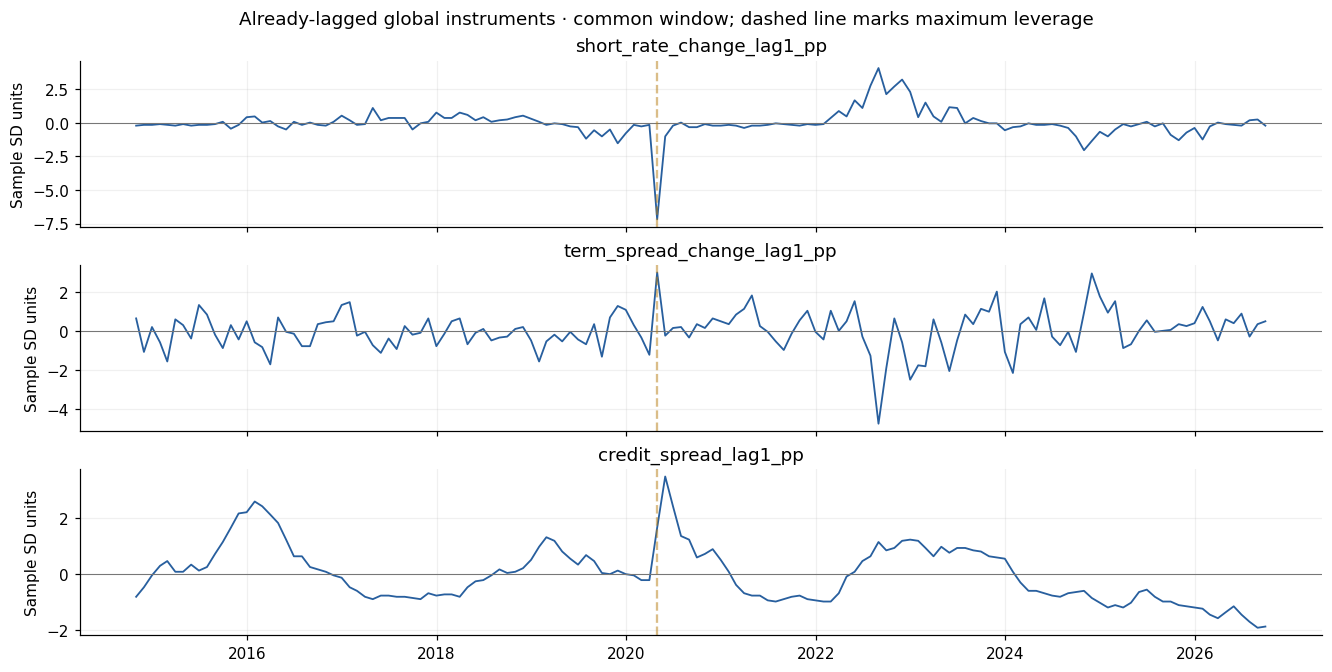

**Audit:** rank 4/4, condition 1.80. Maximum design leverage is 0.406 in 2020-04. Retain the planned set. Persistent credit spreads and unusually influential rate-change observations remain explicit robustness concerns.

In [3]:
fred_path = ROOT/locks["research_synthesis_inputs.json"]["snapshot"]/"raw"/"fred.csv"
assert sha(fred_path.read_bytes()) == input_hashes[fred_path.relative_to(ROOT).as_posix()]
fred = pd.read_csv(fred_path, index_col=0, float_precision="round_trip")
fred.index = pd.PeriodIndex(fred.index, freq="M")
assert fred.index.is_unique
fred = fred.reindex(pd.period_range(fred.index.min(), fred.index.max(), freq="M"))
rebuilt = pd.DataFrame({CANDIDATES[0]: fred.TB3MS.diff().shift(1),
    CANDIDATES[1]: (fred.GS10-fred.TB3MS).diff().shift(1), CANDIDATES[2]: (fred.BAA-fred.AAA).shift(1)}).loc[months]
instruments = frames[("HU", "USD")][CANDIDATES].copy()
np.testing.assert_allclose(rebuilt, instruments, atol=1e-12, rtol=0)
for d in frames.values(): np.testing.assert_array_equal(d[CANDIDATES], instruments)
assert np.isfinite(instruments.to_numpy()).all()
centres, spreads = instruments.mean(), instruments.std(ddof=1)
assert spreads.gt(0).all()
standardised = (instruments-centres)/spreads
Z = np.c_[np.ones(len(months)), standardised[WORLD_INSTRUMENTS].to_numpy()]
assert np.linalg.matrix_rank(Z) == Z.shape[1]
conditioning = pd.DataFrame(Z, index=months, columns=["constant"]+WORLD_INSTRUMENTS)
audit_rows = []
for name in CANDIDATES:
    a = adfuller(instruments[name], maxlag=12, regression="c", autolag="AIC", result_object=False)
    with warnings.catch_warnings(record=True) as caught:
        warnings.simplefilter("always", InterpolationWarning)
        k = kpss(instruments[name], regression="c", nlags="auto", result_object=False)
    bound = (">=" if k[1] >= .1 else "<=") if any(issubclass(w.category, InterpolationWarning) for w in caught) else ""
    vif = variance_inflation_factor(Z, 1+WORLD_INSTRUMENTS.index(name)) if name in WORLD_INSTRUMENTS else np.nan
    audit_rows.append({"instrument": name, "used": name in WORLD_INSTRUMENTS, "n": len(months), "missing": int(instruments[name].isna().sum()),
        "mean_pp": centres[name], "sd_pp": spreads[name], "lag1_correlation": instruments[name].autocorr(),
        "ADF_stat": a[0], "ADF_p_raw": a[1], "ADF_used_lags": a[2], "KPSS_stat": k[0], "KPSS_p_report": f"{bound}{k[1]:.5g}",
        "KPSS_lags": k[2], "VIF_selected_design": vif, "max_abs_z": standardised[name].abs().max(),
        "extreme_month": str(standardised[name].abs().idxmax()), "max_alignment_error": np.abs(rebuilt[name]-instruments[name]).max()})
audit = pd.DataFrame(audit_rows)
leverage_values = np.einsum("ij,jk,ik->i", Z, np.linalg.inv(Z.T@Z), Z)
leverage = pd.DataFrame({"month": months.astype(str), "leverage": leverage_values,
    "reference_2p_over_n": 2*Z.shape[1]/len(Z), "flag_high_leverage": leverage_values > 2*Z.shape[1]/len(Z)})
design_audit = pd.DataFrame([{"months": len(Z), "rank": np.linalg.matrix_rank(Z), "columns": Z.shape[1],
    "condition_number": np.linalg.cond(Z), "max_leverage": leverage_values.max(),
    "max_leverage_month": str(months[leverage_values.argmax()]), "high_leverage_months": int(leverage.flag_high_leverage.sum())}])
transform_table = pd.DataFrame({"instrument": CANDIDATES, "mean_pp": centres.to_numpy(), "sd_pp_ddof1": spreads.to_numpy(),
    "used": [name in WORLD_INSTRUMENTS for name in CANDIDATES]})
figure_files = []
def save_plot(name):
    plt.savefig(OUT/name, dpi=170, bbox_inches="tight", metadata={"Software": "Regional world-pricing notebook 24"})
    figure_files.append(name); plt.show(); plt.close()
display(audit.set_index("instrument").round(5))
display(design_audit.round(5))
display(instruments.corr().round(4))
display(leverage.sort_values("leverage", ascending=False).head(5).round(4))
fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True, layout="constrained")
for ax, name in zip(axes, CANDIDATES):
    ax.plot(months.to_timestamp("M"), standardised[name], color="#285f9e", lw=1.2)
    ax.axhline(0, color="#777777", lw=.7)
    ax.axvline(months[leverage_values.argmax()].to_timestamp("M"), color="#b77d13", alpha=.5, ls="--")
    ax.set(title=name, ylabel="Sample SD units")
fig.suptitle("Already-lagged global instruments · common window; dashed line marks maximum leverage")
save_plot("01_instruments.png")
display(Markdown(f"**Audit:** rank {np.linalg.matrix_rank(Z)}/{Z.shape[1]}, condition {np.linalg.cond(Z):.2f}. "
    f"Maximum design leverage is {leverage_values.max():.3f} in {months[leverage_values.argmax()]}. "
    "Retain the planned set. Persistent credit spreads and unusually influential rate-change observations remain explicit robustness concerns."))

## 3. Change only the world-price function

$$\boxed{\lambda_{W,t}=\kappa_0+\sum_{j=1}^{K}\kappa_j\widetilde Z_{j,t-1},
\qquad \widetilde Z_j=(Z_j-\bar Z_j)/s_j.}$$

The stored columns already have their lag. With centered regressors, kappa0 is the average fitted
world price; a slope is the price change for a one-sample-SD predictor increase. The linear model
allows negative prices. Fitted time variation is not itself evidence that extra slopes are needed.

The varying world price enters **all five conditional means, including both FX equations**,
maintaining notebook 23's corrected pricing restriction. The two FX prices and US/national own-risk
prices remain constant and are jointly re-estimated, along with every covariance parameter.
There are no added equity alphas or FX intercept/VAR corrections. Scalar and diagonal covariance
forms and stationary innovation initialization remain unchanged.

The constant restriction sets only the K world slopes to zero. With the default K=3, parameter
counts rise **22 to 25** (scalar), **30 to 33** (diagonal). Compare identical five-series likelihoods
within country/numeraire. Separate country systems need not estimate the same world coefficients;
we are not fitting a pooled world-price restriction or an independent USD/EUR replication.

In [4]:
check_rows = []
for key, baseline in constant_fits.items():
    country, currency, covariance = key
    y, scale = baseline["y"], baseline["scales"]
    nested_theta = engine.lift_constant(baseline["theta"], Z)
    f = engine.filter_model(nested_theta, y, Z, scale, True, covariance)
    for field in ["H", "mu", "errors", "losses"]: np.testing.assert_allclose(f[field], baseline["filter"][field], atol=1e-12, rtol=0)
    theta = engine.initial_theta(y, Z, scale, True, covariance)
    indices = engine.world_indices(Z, True)
    theta[indices[1:]] = np.linspace(.1, -.08, len(indices)-1)
    if covariance == "diagonal": theta[-10:] += np.linspace(-.1, .1, 10)
    analytic = engine.objective(theta, y[:35], Z[:35], scale, True, covariance)[1]
    numeric = engine.numerical_gradient(lambda t: engine.objective(t, y[:35], Z[:35], scale, True, covariance)[0], theta)
    np.testing.assert_allclose(analytic, numeric, atol=5e-6, rtol=5e-5)
    probe = engine.filter_model(theta, y, Z, scale, True, covariance)
    expected = probe["world_prices"][:, None]*probe["H"][:, :, 0]
    expected += probe["prices"][3]*probe["H"][:, :, 3]+probe["prices"][4]*probe["H"][:, :, 4]
    expected[:, 1] += probe["prices"][1]*probe["H"][:, 1, 1]
    expected[:, 2] += probe["prices"][2]*probe["H"][:, 2, 2]
    np.testing.assert_allclose(probe["mu"], expected, atol=1e-12, rtol=0)
    np.testing.assert_allclose(probe["world_prices"].mean(), engine.PRICE_SCALE*theta[0], atol=1e-12, rtol=0)
    if covariance == "scalar":
        other = engine.filter_model(engine.expand_scalar(theta), y, Z, scale, True, "diagonal")
        for field in ["H", "mu", "losses"]: np.testing.assert_allclose(probe[field], other[field], atol=1e-12, rtol=0)
    check_rows.append({"country": country, "perspective": currency, "covariance": covariance,
        "parameters": len(theta), "max_gradient_error": np.abs(analytic-numeric).max(),
        "constant_nesting_max_H_error": np.abs(f["H"]-baseline["filter"]["H"]).max()})
checks = pd.DataFrame(check_rows)
display(checks.groupby("covariance")[["parameters", "max_gradient_error", "constant_nesting_max_H_error"]].max())
print("All 20 gradient/nesting checks and corrected five-mean identities pass after the instrument audit.")

,parameters,max_gradient_error,constant_nesting_max_H_error
covariance,,,
diagonal,33,5.816767e-08,0.0
scalar,25,4.741300e-08,0.0


All 20 gradient/nesting checks and corrected five-mean identities pass after the instrument audit.


## 4. Fit conditional-world models from nested and independent starts

Use the matching constant optimum with zero world slopes, two moment/dynamics starts, and for
diagonal covariance the fitted conditional scalar solution. Require optimizer success and maximum
projected gradient below 0.0001, recording the raw gradient and all starting-point outcomes. Stop
if a lower nonconverged candidate remains or the selected fit is worse than a nested parent.

Cache fingerprints include data, the common conditioning matrix, engine/dependency hashes,
normalization, settings, runtime and exact start vectors. Re-filter and recheck saved fits before
reuse. Only this notebook's output configuration folder is written. Starting-point agreement is
useful numerical evidence, not proof of a global optimum.

In [5]:
fits, start_rows = {}, []
for key, y in samples.items():
    country, currency = key
    for covariance in COVARIANCES:
        print(f"{NAMES[country]} · {currency} · {covariance} · time-varying world", flush=True)
        baseline = constant_fits[(*key, covariance)]
        starts = [engine.lift_constant(baseline["theta"], Z)]
        labels = ["verified constant-world reference"]
        starts += [engine.initial_theta(y, Z, scales[key], True, covariance, a, b) for a, b in START_DYNAMICS]
        labels += [f"moment dynamics {a:g}/{b:g}" for a, b in START_DYNAMICS]
        if covariance == "diagonal":
            starts.insert(0, engine.expand_scalar(fits[(*key, "scalar")]["theta"]))
            labels.insert(0, "nested conditional scalar solution")
        config = {"version": MODEL_VERSION, "engines": engine_hashes, "country": country, "perspective": currency,
            "covariance": covariance, "source_sha256": source_hashes[key], "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA,
            "first": str(months[0]), "last": str(months[-1]), "world_instruments": WORLD_INSTRUMENTS,
            "centres": centres[WORLD_INSTRUMENTS].to_dict(), "spreads_ddof1": spreads[WORLD_INSTRUMENTS].to_dict(),
            "start_labels": labels, "start_hashes": [sha(t.tobytes()) for t in starts], "max_iter": MAX_ITER,
            "packages": versions, "python": platform.python_version()}
        fingerprint = sha(json.dumps(config, sort_keys=True).encode()+y.tobytes()+Z.tobytes())
        path = OUT/f"fit_{country}_{currency}_{covariance}_time_varying.json"
        record = json.loads(path.read_text()) if REUSE_FITS and path.exists() else None
        limits = engine.bounds(Z, True, covariance)
        if record is not None and record.get("fingerprint") == fingerprint:
            theta = np.asarray(record["theta"])
            value, gradient = engine.objective(theta, y, Z, scales[key], True, covariance)
            valid = (record.get("optimizer_success") and np.isfinite(value) and abs(value-record["mean_nll"]) < 1e-8
                and np.abs(engine.projected_gradient(theta, gradient, limits)).max() < 1e-4
                and ((theta >= limits[:, 0]) & (theta <= limits[:, 1])).all())
            if not valid: record = None
        else: record = None
        if record is None:
            best, runs = engine.fit_starts(y, Z, scales[key], True, covariance, starts, MAX_ITER)
            record = {"fingerprint": fingerprint, "config": config, "theta": best.x.tolist(),
                "mean_nll": float(best.fun), "optimizer_success": bool(best.success), "starts": runs}
            temp = path.with_suffix(".tmp")
            temp.write_text(json.dumps(record, indent=2, sort_keys=True)+"\n"); temp.replace(path)
        else: print("  verified cached fit", flush=True)
        theta = np.asarray(record["theta"])
        f = engine.filter_model(theta, y, Z, scales[key], True, covariance)
        assert f["losses"].sum() <= baseline["filter"]["losses"].sum()+1e-5
        if covariance == "diagonal": assert f["losses"].sum() <= fits[(*key, "scalar")]["filter"]["losses"].sum()+1e-5
        fits[(*key, covariance)] = {"theta": theta, "filter": f, "varying": True, "y": y, "scales": scales[key], "record": record}
        start_rows.extend({"country": country, "perspective": currency, "covariance": covariance,
            "start_label": labels[r["start"]-1], **r} for r in record["starts"])
starts_table = pd.DataFrame(start_rows, columns=["country", "perspective", "covariance", "start_label", "start", "success",
    "mean_nll", "max_abs_gradient", "max_projected_gradient", "iterations", "refined", "message"])
display(starts_table.groupby(["country", "perspective", "covariance"]).agg(starts=("start", "count"), successes=("success", "sum"),
    best_NLL=("mean_nll", "min"), worst_NLL=("mean_nll", "max"), worst_projected_gradient=("max_projected_gradient", "max")).round(7))
all_fits = {**{(*k, "constant"): f for k, f in constant_fits.items()}, **{(*k, "time_varying"): f for k, f in fits.items()}}

Hungary · USD · scalar · time-varying world


  start 1: success=True, NLL=10.946522676, raw=1.70e-06, projected=1.70e-06, iterations=164


  start 2: success=True, NLL=10.946522676, raw=5.31e-07, projected=5.31e-07, iterations=207


  start 3: success=True, NLL=10.946522676, raw=1.76e-06, projected=1.76e-06, iterations=181


Hungary · USD · diagonal · time-varying world


  start 1: success=True, NLL=10.883842519, raw=2.97e-04, projected=1.80e-06, iterations=1326


... (81 outputs left out)

  start 2: success=True, NLL=10.175282092, raw=6.55e-07, projected=6.55e-07, iterations=367


  start 3: success=True, NLL=10.175282342, raw=8.21e-07, projected=8.21e-07, iterations=402


  start 4: success=True, NLL=10.175282091, raw=1.79e-06, projected=1.79e-06, iterations=475


starts  successes   best_NLL  worst_NLL  \
country perspective covariance                                            
CZ      EUR         diagonal         4          4  10.005772  10.008124   
                    scalar           3          3  10.054353  10.054353   
        USD         diagonal         4          4  10.038759  10.039262   
                    scalar           3          3  10.062886  10.062886   
HU      EUR         diagonal         4          4  10.886861  10.886861   
                    scalar           3          3  10.934376  10.934376   
        USD         diagonal         4          4  10.883843  10.892012   
                    scalar           3          3  10.946523  10.946523   
PL      EUR         diagonal         4          4  10.380510  10.383852   
                    scalar           3          3  10.421230  10.421230   
        USD         diagonal         4          4  10.355272  10.362627   
                    scalar           3          3  10.430153  10.430153   
RO      EUR         diagonal         4          4   9.737049   9.737049   
                    scalar           3          3   9.759671   9.759671   
        USD         diagonal         4          4   9.666141   9.668378   
                    scalar           3          3   9.768450   9.768450   
SE      EUR         diagonal         4          4  10.175282  10.175282   
                    scalar           3          3  10.207840  10.207840   
        USD         diagonal         4          4  10.191849  10.193133   
                    scalar           3          3  10.215236  10.215236   

                                worst_projected_gradient  
country perspective covariance                            
CZ      EUR         diagonal                3.500000e-06  
                    scalar                  1.200000e-06  
        USD         diagonal                5.140000e-05  
                    scalar                  9.000000e-07  
HU      EUR         diagonal                4.410000e-05  
                    scalar                  8.000000e-07  
        USD         diagonal                8.800000e-06  
                    scalar                  1.800000e-06  
PL      EUR         diagonal                4.400000e-06  
                    scalar                  4.700000e-06  
        USD         diagonal                1.600000e-06  
                    scalar                  1.500000e-06  
RO      EUR         diagonal                3.700000e-06  
                    scalar                  1.600000e-06  
        USD         diagonal                3.800000e-06  
                    scalar                  2.400000e-06  
SE      EUR         diagonal                1.800000e-06  
                    scalar                  1.100000e-06  
        USD         diagonal                9.600000e-06  
                    scalar                  3.000000e-06

## 5. Robust inference and pointwise world-price uncertainty

Use the full joint robust QML sandwich and fixed Bartlett score-HAC lags **0, 3, 6, 12**. Check
two Hessian steps, parameter bounds, curvature/conditioning and risk-price SE stability. Also
check stability of the world-path standard errors. Suppress unavailable inference and record reasons.

Test the world slopes **jointly zero** (3 df under the default design), separately from an
identically zero world price, zero FX prices and zero local prices. These exploratory asymptotic
p-values are unadjusted. With short samples, persistent conditioners and high leverage, nominal
significance does not establish stable predictability or causal economic effects.

Pointwise world-price intervals use the price-coefficient block of the full joint covariance and
the fixed observed design. They are **not simultaneous bands or return prediction intervals**.
All nuisance covariance and price parameters are jointly estimated; HAC does not repair an
inadequate mean/covariance model. Unavailable inference is not a non-rejection.

In [6]:
fit_rows, coefficient_rows, test_rows, inference_rows, boundary_rows, path_rows = [], [], [], [], [], []
for (country, currency, covariance, model), fit in all_fits.items():
    theta, f, y, varying = fit["theta"], fit["filter"], fit["y"], fit["varying"]
    info = engine.inference(theta, y, Z, fit["scales"], varying, covariance, f, HAC_LAGS)
    fit["inference"] = info
    tags = {"country": country, "perspective": currency, "covariance": covariance, "model": model}
    world_ids = engine.world_indices(Z, varying)
    labels = ["World intercept scaled", "US local scaled", "National local scaled", "National FX scaled", "Other FX scaled"]
    if varying: labels += [f"World slope {name}" for name in WORLD_INSTRUMENTS]
    labels += [f"{'log ' if i == j else ''}C[{i+1},{j+1}]" for i, j in zip(*engine.TRI)]
    labels += [f"{asset} {parameter} logit" for asset in (ASSETS if covariance == "diagonal" else ["Shared"]) for parameter in ["alpha", "beta"]]
    limits = engine.bounds(Z, varying, covariance)
    distance = np.minimum(theta-limits[:, 0], limits[:, 1]-theta)
    boundary_rows.extend({**tags, "parameter": label, "coordinate": theta[j], "lower": limits[j, 0], "upper": limits[j, 1],
        "distance_to_bound": distance[j], "near_bound": bool(distance[j] < 1e-4)} for j, label in enumerate(labels))
    LL, gradient = -f["losses"].sum(), f["scores"].mean(axis=0)
    fit_rows.append({**tags, "n": len(y), "parameters": len(theta), "loglik": LL, "AIC": -2*LL+2*len(theta),
        "BIC": -2*LL+np.log(len(y))*len(theta), "max_abs_gradient": np.abs(gradient).max(),
        "max_projected_gradient": np.abs(engine.projected_gradient(theta, gradient, limits)).max(),
        "min_H_eigenvalue": np.linalg.eigvalsh(f["H"]).min(), "bound_parameters": "; ".join(label for j, label in enumerate(labels) if distance[j] < 1e-4),
        **{name: info[name] for name in ["Hessian_min_eigenvalue", "Hessian_condition", "Hessian_step_difference", "min_distance_to_bounds"]}})
    coefficient_map = [("World", name, j) for name, j in zip(["constant"]+(WORLD_INSTRUMENTS if varying else []), world_ids)]
    coefficient_map += [(risk, "constant", j) for j, risk in [(1, "US local"), (2, "National local"), (3, "National FX"), (4, "Other FX")]]
    for lag, estimate in info["estimates"].items():
        ready, V = estimate["ready"], estimate["covariance"]
        inference_rows.append({**tags, "HAC_lag": lag, "ready": ready, "reason": estimate["reason"],
            "price_SE_step_difference": estimate["price_SE_step_difference"], "world_path_SE_step_difference": estimate["world_path_SE_step_difference"]})
        for risk, name, j in coefficient_map:
            value, se = engine.PRICE_SCALE*theta[j], engine.PRICE_SCALE*np.sqrt(V[j, j]) if ready else np.nan
            coefficient_rows.append({**tags, "risk": risk, "term": name, "HAC_lag": lag, "estimate": value, "robust_se": se,
                "p_value": 2*norm.sf(abs(value/se)) if ready else np.nan, "ci95_low": value-1.96*se,
                "ci95_high": value+1.96*se, "inference_ready": ready, "reason": estimate["reason"]})
        restrictions = [("World price identically zero", world_ids), ("FX prices jointly zero", [3, 4]),
            ("National local price zero", [2]), ("Both local prices zero", [1, 2])]
        if varying: restrictions.insert(0, ("World price constant", world_ids[1:]))
        for name, ids in restrictions:
            value, variance = theta[ids], V[np.ix_(ids, ids)]
            valid = ready and np.linalg.eigvalsh(variance).min() > 0 and np.linalg.cond(variance) < 1e9
            statistic = value@np.linalg.solve(variance, value) if valid else np.nan
            test_rows.append({**tags, "HAC_lag": lag, "restriction": name, "df": len(ids), "Wald_statistic": statistic,
                "p_value": chi2.sf(statistic, len(ids)) if valid else np.nan, "inference_ready": valid,
                "reason": estimate["reason"] if not ready or valid else "unstable restriction covariance"})
        design = Z if varying else np.ones((len(y), 1))
        variance = engine.PRICE_SCALE**2*np.einsum("ij,jk,ik->i", design, V[np.ix_(world_ids, world_ids)], design) if ready else np.full(len(y), np.nan)
        se = np.sqrt(variance)
        for t, month in enumerate(months):
            path_rows.append({**tags, "HAC_lag": lag, "month": str(month), "world_price": f["world_prices"][t], "robust_se": se[t],
                "ci95_low": f["world_prices"][t]-1.96*se[t], "ci95_high": f["world_prices"][t]+1.96*se[t], "inference_ready": ready})
fit_table, coefficients, tests, inference_audit, boundary_audit, world_paths = map(pd.DataFrame,
    [fit_rows, coefficient_rows, test_rows, inference_rows, boundary_rows, path_rows])
display(inference_audit.query("HAC_lag == 0").groupby(["covariance", "model", "ready", "reason"]).size().rename("systems"))
display(tests.query("restriction == 'World price constant'").pivot(index=["country", "perspective", "covariance"], columns="HAC_lag", values="p_value").round(5))

covariance  model         ready  reason                                    
diagonal    constant      False  parameter bound                                1
                                 parameter bound; ill-conditioned curvature     6
                          True   numerically ready                              3
            time_varying  False  parameter bound                                1
                                 parameter bound; ill-conditioned curvature     5
                          True   numerically ready                              4
scalar      constant      True   numerically ready                             10
            time_varying  True   numerically ready                             10
Name: systems, dtype: int64

HAC_lag                              0        3        6        12
country perspective covariance                                    
CZ      EUR         diagonal    0.18420  0.03283  0.03627  0.04310
                    scalar      0.11365  0.05302  0.09389  0.17032
        USD         diagonal    0.06093  0.01473  0.01906  0.02848
                    scalar      0.07337  0.05530  0.09951  0.16397
HU      EUR         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.02498  0.00543  0.00704  0.00726
        USD         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.02681  0.01221  0.01552  0.02185
PL      EUR         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.04494  0.00633  0.00691  0.00653
        USD         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.03953  0.00800  0.00819  0.00949
RO      EUR         diagonal    0.04370  0.00532  0.00373  0.00340
                    scalar      0.01301  0.00067  0.00042  0.00037
        USD         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.01536  0.00005  0.00000  0.00000
SE      EUR         diagonal        NaN      NaN      NaN      NaN
                    scalar      0.02502  0.00302  0.00289  0.00324
        USD         diagonal    0.02690  0.00302  0.00185  0.00029
                    scalar      0.02764  0.00027  0.00012  0.00003

## 6. Residual adequacy and model-comparison limits

Repeat notebook 23's five marginal innovation/squared-innovation/ARCH screens and ten whitened
cross-product screens. Holm families are covariance × world-price form × investor currency × test
type (25 marginal or 50 pair series across countries). Keep raw and adjusted values. These remain
approximate post-GARCH diagnostics, not full degrees-of-freedom-adjusted specification tests.

Compare AIC/BIC within the same country, currency and covariance model. Time variation adds the
selected K slopes; nominal parameter counts are retained at bounds. Do not rank different countries
or investor currencies by likelihood levels. Fitted paths and criterion improvements alone do not
validate the pricing restriction. No ordinary Gaussian LR chi-square p-value is reported under QML.

In [7]:
residual_rows, cross_rows = [], []
for (country, currency, covariance, model), fit in all_fits.items():
    f = fit["filter"]
    tags = {"country": country, "perspective": currency, "covariance": covariance, "model": model}
    z = f["errors"]/np.sqrt(np.diagonal(f["H"], axis1=1, axis2=2))
    white = np.linalg.solve(np.linalg.cholesky(f["H"]), f["errors"][..., None])[..., 0]
    lb = lambda s: acorr_ljungbox(s, lags=[TEST_LAGS], return_df=True).lb_pvalue.iloc[0]
    for j, asset in enumerate(ASSETS):
        residual_rows.append({**tags, "asset": asset, "z_mean": z[:, j].mean(), "z_sd": z[:, j].std(ddof=1),
            "LB_z_p": lb(z[:, j]), "LB_z_squared_p": lb((z[:, j]-z[:, j].mean())**2),
            "ARCH_LM_p": het_arch(z[:, j], nlags=TEST_LAGS, ddof=0, result_object=False)[1]})
    for i, j in zip(*np.triu_indices(5, 1)):
        product = white[:, i]*white[:, j]
        cross_rows.append({**tags, "pair": f"{ASSETS[i]}/{ASSETS[j]}", "mean_whitened_product": product.mean(), "LB_product_p": lb(product)})
residuals, cross = pd.DataFrame(residual_rows), pd.DataFrame(cross_rows)
for frame, columns in [(residuals, ["LB_z_p", "LB_z_squared_p", "ARCH_LM_p"]), (cross, ["LB_product_p"])]:
    for _, idx in frame.groupby(["covariance", "model", "perspective"]).groups.items():
        for column in columns: frame.loc[idx, column+"_holm"] = multipletests(frame.loc[idx, column], method="holm")[1]
display(residuals.query("model == 'time_varying' and asset == 'National FX'").set_index(["country", "perspective", "covariance"])
    [["z_mean", "z_sd", "LB_z_p", "LB_z_p_holm", "ARCH_LM_p", "ARCH_LM_p_holm"]].round(5))

z_mean     z_sd   LB_z_p  LB_z_p_holm  \
country perspective covariance                                           
HU      USD         scalar     -0.00878  1.01015  0.97687      1.00000   
                    diagonal   -0.01318  1.00518  0.97203      1.00000   
        EUR         scalar     -0.01043  1.01028  0.76750      1.00000   
                    diagonal    0.00199  1.01524  0.83759      1.00000   
PL      USD         scalar     -0.01569  0.99969  0.95667      1.00000   
                    diagonal   -0.02083  1.00931  0.95280      1.00000   
        EUR         scalar     -0.02557  0.99953  0.47087      1.00000   
                    diagonal   -0.01693  1.00673  0.32719      1.00000   
CZ      USD         scalar     -0.02024  1.01361  0.91451      1.00000   
                    diagonal   -0.04782  1.01248  0.94963      1.00000   
        EUR         scalar     -0.01910  1.01963  0.36823      1.00000   
                    diagonal   -0.03543  1.02734  0.23776      1.00000   
RO      USD         scalar      0.01152  0.98844  0.96969      1.00000   
                    diagonal   -0.06388  0.92645  0.97576      1.00000   
        EUR         scalar      0.02981  1.01176  0.02052      0.51291   
                    diagonal    0.03606  1.00150  0.03089      0.77235   
SE      USD         scalar     -0.00098  0.99984  0.99947      1.00000   
                    diagonal   -0.02100  1.00027  0.99925      1.00000   
        EUR         scalar     -0.02992  0.99075  0.38801      1.00000   
                    diagonal   -0.04100  0.99077  0.39809      1.00000   

                                ARCH_LM_p  ARCH_LM_p_holm  
country perspective covariance                             
HU      USD         scalar        0.74499             1.0  
                    diagonal      0.63107             1.0  
        EUR         scalar        0.82414             1.0  
                    diagonal      0.97555             1.0  
PL      USD         scalar        0.29767             1.0  
                    diagonal      0.21005             1.0  
        EUR         scalar        0.81471             1.0  
                    diagonal      0.74757             1.0  
CZ      USD         scalar        0.31095             1.0  
                    diagonal      0.32370             1.0  
        EUR         scalar        0.92997             1.0  
                    diagonal      0.93400             1.0  
RO      USD         scalar        0.97253             1.0  
                    diagonal      0.95776             1.0  
        EUR         scalar        0.28041             1.0  
                    diagonal      0.45811             1.0  
SE      USD         scalar        0.76427             1.0  
                    diagonal      0.78751             1.0  
        EUR         scalar        0.90538             1.0  
                    diagonal      0.85680             1.0

## 7. World-price paths and national equity premium contributions

Show one path per country/investor/covariance system, beside its own constant reference. Bands,
where available, use primary lag-0 pointwise robust uncertainty. A path without a band is a point
estimate with suppressed inference. Do not infer evidence for world-price variation from the shape
alone. The four bandwidth results remain in the tables.

National equity premiums still split into time-varying world price × world covariance, constant
national-FX/other-FX prices × their covariances, and constant own-local price × own variance. Keep
separate FX contributions and changing covariances visible in the exported monthly decomposition.
No hedged-return or hedging-cost comparison is estimated here.

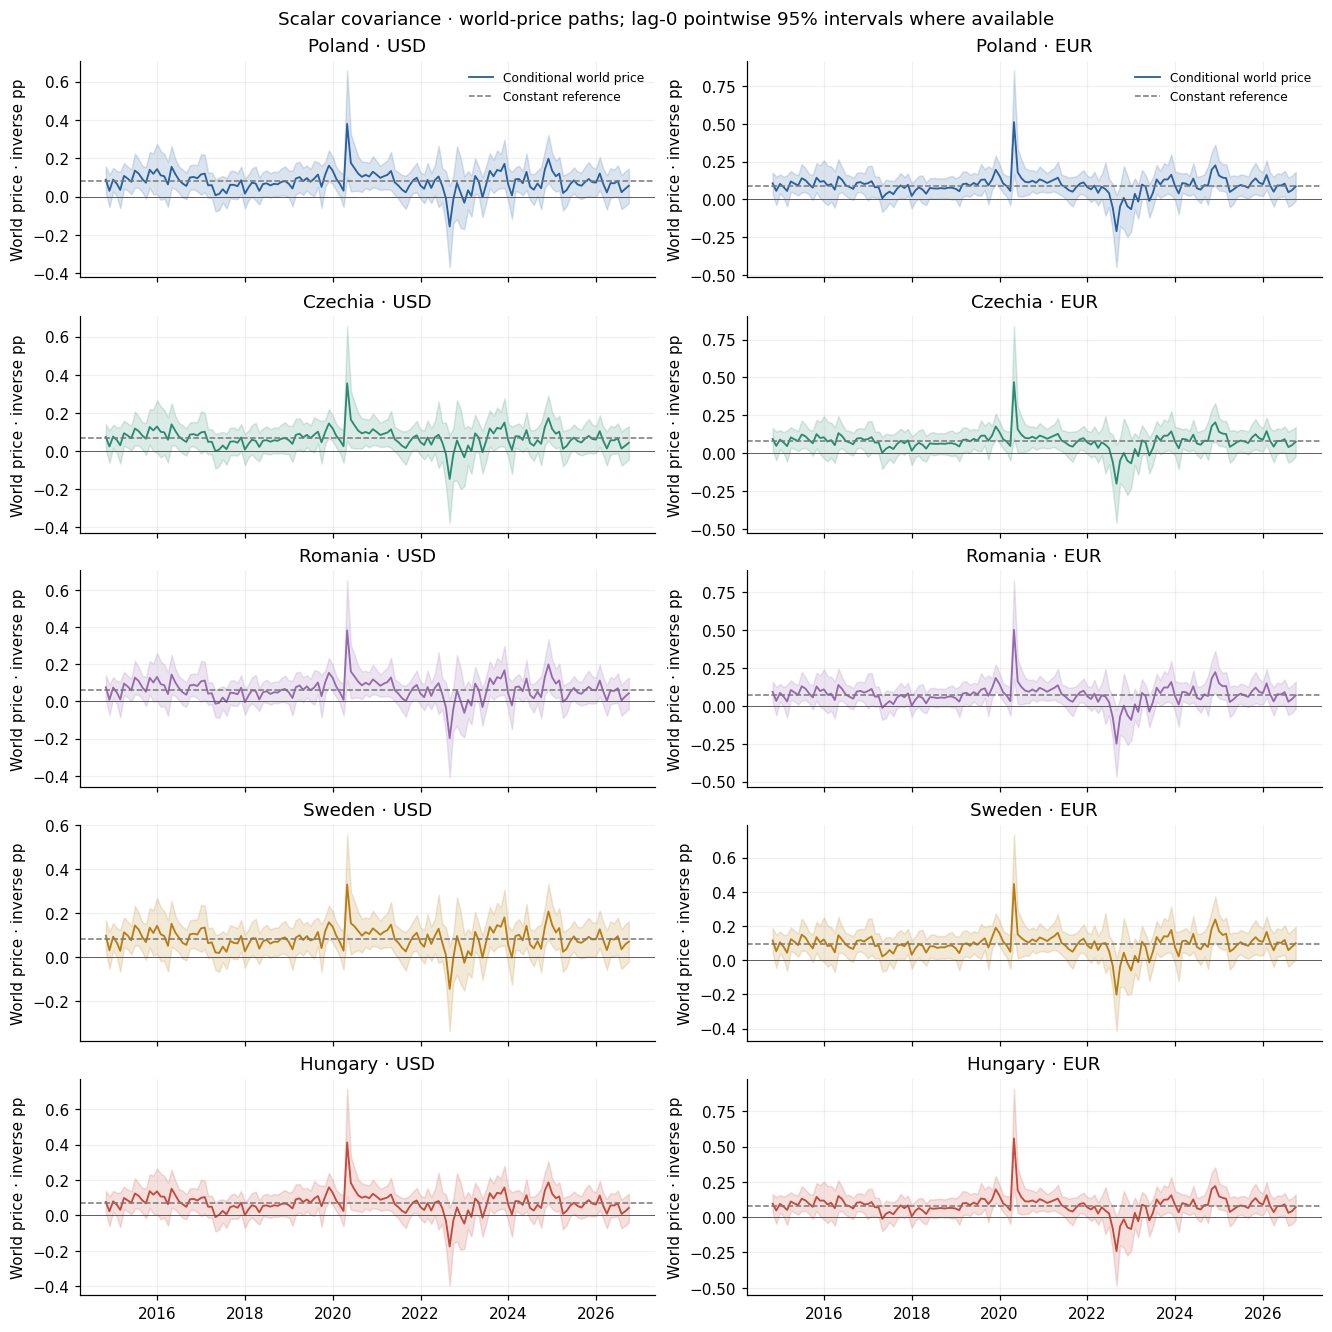

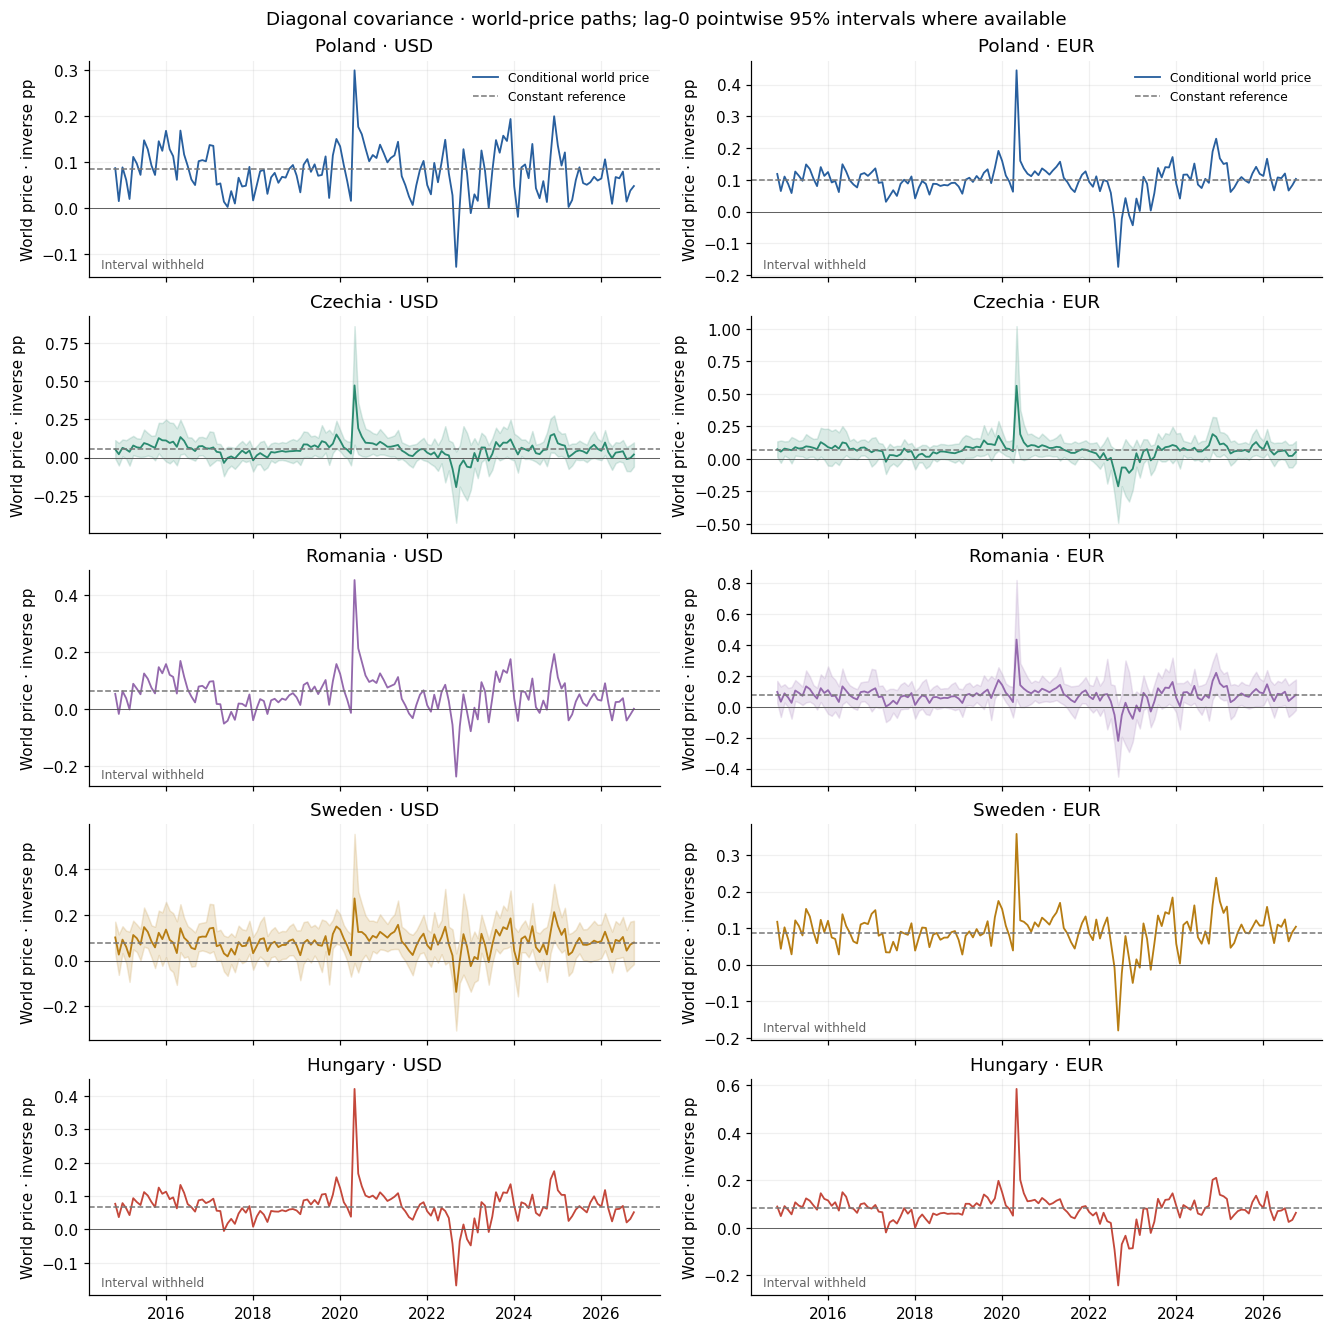

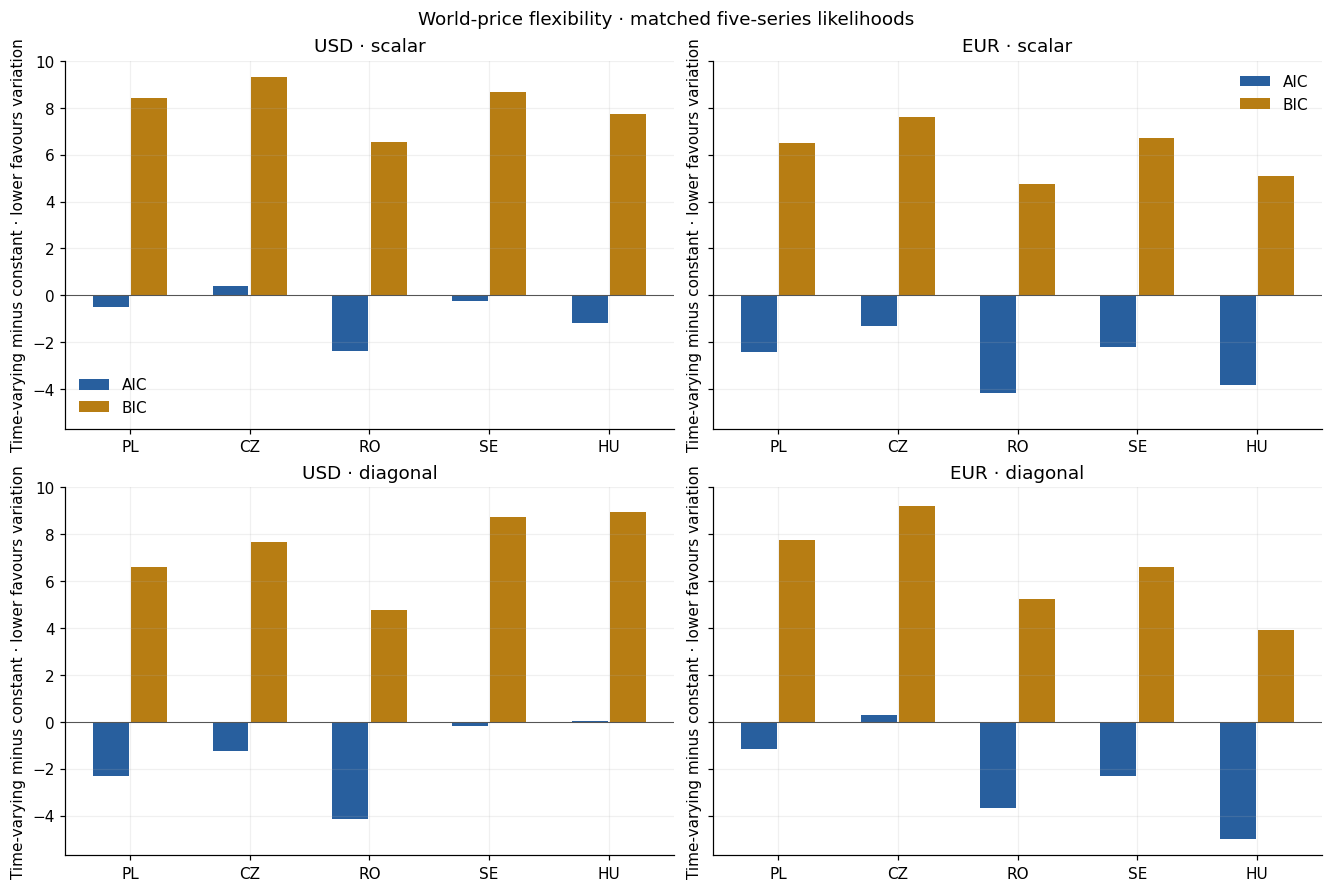

In [8]:
premium_rows, summary_rows, comparison_rows = [], [], []
for (country, currency, covariance, model), fit in all_fits.items():
    f = fit["filter"]
    components = {"world": f["world_prices"]*f["H"][:, 2, 0], "national_FX": f["prices"][3]*f["H"][:, 2, 3],
        "other_FX": f["prices"][4]*f["H"][:, 2, 4], "local": f["prices"][2]*f["H"][:, 2, 2]}
    total = sum(components.values())
    np.testing.assert_allclose(total, f["mu"][:, 2], atol=1e-11, rtol=0)
    np.testing.assert_allclose(f["world_prices"].mean(), engine.PRICE_SCALE*fit["theta"][0], atol=1e-12, rtol=0)
    for t, month in enumerate(months):
        premium_rows.append({"country": country, "perspective": currency, "covariance": covariance, "model": model, "month": str(month),
            "world_price": f["world_prices"][t], **{name+"_premium_pp": values[t] for name, values in components.items()},
            "currency_total_pp": components["national_FX"][t]+components["other_FX"][t], "fitted_mean_pp": total[t],
            "world_covariance_pp2": f["H"][t, 2, 0], "national_FX_price": f["prices"][3], "other_FX_price": f["prices"][4]})
    if model != "time_varying": continue
    same = fit_table.query("country == @country and perspective == @currency and covariance == @covariance").set_index("model")
    choose = lambda name, lag: tests.loc[(tests.country == country) & (tests.perspective == currency) & (tests.covariance == covariance)
        & (tests.model == model) & (tests.restriction == name) & (tests.HAC_lag == lag), "p_value"].iloc[0]
    r = residuals.query("country == @country and perspective == @currency and covariance == @covariance and model == 'time_varying'")
    c = cross.query("country == @country and perspective == @currency and covariance == @covariance and model == 'time_varying'")
    delta_AIC = same.loc["time_varying", "AIC"]-same.loc["constant", "AIC"]
    delta_BIC = same.loc["time_varying", "BIC"]-same.loc["constant", "BIC"]
    comparison_rows.append({"country": country, "perspective": currency, "covariance": covariance, "delta_AIC": delta_AIC,
        "delta_BIC": delta_BIC, "loglik_gain": same.loc["time_varying", "loglik"]-same.loc["constant", "loglik"]})
    summary_rows.append({"country": country, "name": NAMES[country], "perspective": currency, "covariance": covariance, "months": len(months),
        "world_constancy_p_QML": choose("World price constant", 0), "world_constancy_p_HAC12": choose("World price constant", 12),
        "world_zero_p_QML": choose("World price identically zero", 0), "FX_joint_p_QML": choose("FX prices jointly zero", 0),
        "delta_AIC": delta_AIC, "delta_BIC": delta_BIC, "constant_world_price": constant_fits[(country, currency, covariance)]["filter"]["prices"][0],
        "world_price_mean": f["world_prices"].mean(), "world_price_min": f["world_prices"].min(), "world_price_max": f["world_prices"].max(),
        "world_price_negative_pct": 100*np.mean(f["world_prices"] < 0), "mean_world_premium_pp": components["world"].mean(),
        "mean_currency_total_pp": (components["national_FX"]+components["other_FX"]).mean(), "mean_local_premium_pp": components["local"].mean(),
        "numerical_inference_ready": fit["inference"]["estimates"][0]["ready"], "inference_reason": fit["inference"]["estimates"][0]["reason"],
        "mean_flags_raw_5pct": int(r.LB_z_p.lt(.05).sum()), "mean_flags_holm_5pct": int(r.LB_z_p_holm.lt(.05).sum()),
        "variance_flags_raw_5pct": int((r.LB_z_squared_p.lt(.05) | r.ARCH_LM_p.lt(.05)).sum()),
        "variance_flags_holm_5pct": int((r.LB_z_squared_p_holm.lt(.05) | r.ARCH_LM_p_holm.lt(.05)).sum()),
        "cross_flags_raw_5pct": int(c.LB_product_p.lt(.05).sum()), "cross_flags_holm_5pct": int(c.LB_product_p_holm.lt(.05).sum())})
premiums, summary, comparison = map(pd.DataFrame, [premium_rows, summary_rows, comparison_rows])
for covariance in COVARIANCES:
    fig, axes = plt.subplots(5, 2, figsize=(12, 12), sharex=True, layout="constrained")
    for row, country in enumerate(NAMES):
        for col, currency in enumerate(CURRENCIES):
            ax = axes[row, col]
            p = world_paths.query("country == @country and perspective == @currency and covariance == @covariance and model == 'time_varying' and HAC_lag == 0")
            dates = months.to_timestamp("M")
            ax.plot(dates, p.world_price, color=COLORS[country], lw=1.2, label="Conditional world price")
            ax.axhline(constant_fits[(country, currency, covariance)]["filter"]["prices"][0], color="#777777", ls="--", lw=1, label="Constant reference")
            if p.inference_ready.all(): ax.fill_between(dates, p.ci95_low, p.ci95_high, color=COLORS[country], alpha=.17)
            else: ax.text(.02, .04, "Interval withheld", transform=ax.transAxes, color="#666666", fontsize=8)
            ax.axhline(0, color="#555555", lw=.6)
            ax.set(title=f"{NAMES[country]} · {currency}", ylabel="World price · inverse pp")
            if row == 0: ax.legend(frameon=False, fontsize=8)
    fig.suptitle(f"{covariance.capitalize()} covariance · world-price paths; lag-0 pointwise 95% intervals where available")
    save_plot(f"02_world_prices_{covariance}.png")

fig, axes = plt.subplots(2, 2, figsize=(12, 8), sharey=True, layout="constrained")
for row, covariance in enumerate(COVARIANCES):
    for col, currency in enumerate(CURRENCIES):
        ax = axes[row, col]
        p = comparison.query("perspective == @currency and covariance == @covariance").set_index("country").loc[list(NAMES)]
        x = np.arange(5)
        ax.bar(x-.16, p.delta_AIC, width=.3, color="#285f9e", label="AIC")
        ax.bar(x+.16, p.delta_BIC, width=.3, color="#b77d13", label="BIC")
        ax.axhline(0, color="#555555", lw=.7)
        ax.set(xticks=x, xticklabels=list(NAMES), title=f"{currency} · {covariance}", ylabel="Time-varying minus constant · lower favours variation")
        if row == 0: ax.legend(frameon=False)
fig.suptitle("World-price flexibility · matched five-series likelihoods")
save_plot("03_model_comparison.png")

## 8. Final comparison and reproducibility

Keep instrument validity, numerical convergence, inference readiness and residual adequacy separate.
Credit-spread persistence is inconclusive in the short window; extreme rate-change observations can
dominate a fitted slope. The leverage audit identifies influence concerns, not an observation-deletion
rule. Preserve this concern for targeted robustness before strong economic conclusions.

Compare every country with Hungary using the same months and normalization. Available constancy
tests are conditional on the specification; missing tests remain unavailable. The next research
stage is time-varying FX prices with its own instrument audit, while local prices remain a separate
extension. No hedge-return or economic-drag conclusion follows from this notebook alone.

In [9]:
display(summary.set_index(["name", "perspective", "covariance"])[["world_constancy_p_QML", "world_constancy_p_HAC12",
    "delta_AIC", "delta_BIC", "world_price_mean", "world_price_negative_pct", "numerical_inference_ready"]].round(5))
display(summary.set_index(["name", "perspective", "covariance"])[["inference_reason", "mean_flags_holm_5pct", "variance_flags_holm_5pct", "cross_flags_holm_5pct"]])
tables = {"input_audit.csv": input_audit, "instrument_audit.csv": audit, "design_audit.csv": design_audit,
    "instrument_transform.csv": transform_table, "conditioning_design.csv": conditioning.reset_index(),
    "audited_instruments.csv": instruments.reset_index(), "instrument_correlations.csv": instruments.corr().reset_index(names="instrument"),
    "instrument_leverage.csv": leverage, "implementation_checks.csv": checks, "starting_points.csv": starts_table,
    "fit_summary.csv": fit_table, "price_coefficients.csv": coefficients, "restriction_tests.csv": tests,
    "inference_audit.csv": inference_audit, "parameter_bounds.csv": boundary_audit, "world_price_paths.csv": world_paths,
    "residual_diagnostics.csv": residuals, "cross_covariance_diagnostics.csv": cross,
    "premium_components.csv": premiums, "model_comparison.csv": comparison, "common_comparison.csv": summary}
for name, frame in tables.items(): frame.to_csv(OUT/name, index=False, float_format="%.17g", lineterminator="\n")
parameter_files = []
for (country, currency, covariance, model), fit in all_fits.items():
    name = f"parameters_{country}_{currency}_{covariance}_{model}.npz"
    f = fit["filter"]
    np.savez(OUT/name, theta=fit["theta"], H=f["H"], mu=f["mu"], errors=f["errors"], scores=f["scores"],
        target=f["target"], intercept=f["intercept"], Hessian=fit["inference"]["Hessian"],
        **{f"covariance_HAC{h}": e["covariance"] for h, e in fit["inference"]["estimates"].items()})
    parameter_files.append(name)
_, after_hashes = verify_inputs()
assert input_hashes == after_hashes and engine_hashes == {name: sha((ROOT/name).read_bytes()) for name in engine_hashes}
outputs = [*tables, *figure_files, *parameter_files]+[f"fit_{c}_{p}_{v}_time_varying.json" for c, p, v in fits]
metadata = {"notebook": "24_regional_time_varying_world.ipynb", "model_version": MODEL_VERSION, "engines": engine_hashes,
    "previous_manifest_sha256": PREVIOUS_MANIFEST_SHA, "first": str(months[0]), "last": str(months[-1]), "observations_per_fit": len(months),
    "estimated_fits": len(fits), "constant_reference_fits": len(constant_fits), "input_locks": LOCK_HASHES, "input_file_hashes": input_hashes,
    "world_instruments": WORLD_INSTRUMENTS, "conditioning_rank": int(np.linalg.matrix_rank(Z)), "conditioning_condition": np.linalg.cond(Z),
    "centres": centres.to_dict(), "spreads_ddof1": spreads.to_dict(), "conditioning_sha256": sha(Z.tobytes()),
    "settings": {"START_DYNAMICS": START_DYNAMICS, "MAX_ITER": MAX_ITER, "TEST_LAGS": TEST_LAGS, "HAC_LAGS": HAC_LAGS},
    "python": sys.executable, "python_version": platform.python_version(), "packages": versions,
    "outputs": {name: sha((OUT/name).read_bytes()) for name in outputs},
    "notes": ["Same frozen 144 months; identical lagged global design for five countries and USD/EUR",
        "Audit reconstructs already-lagged financial predictors from raw FRED; no additional lag or data revisions",
        "World price linear in standardized common-window predictors; FX/local prices constant and jointly re-estimated",
        "Corrected priced FX means; zero alphas; scalar and diagonal covariance retained",
        "Fixed QML/HAC 0/3/6/12; pointwise price intervals; invalid inference suppressed",
        "Persistent credit spreads and high-leverage rate-change observations remain robustness concerns"]}
(OUT/"estimation_manifest.json").write_text(json.dumps(metadata, indent=2, sort_keys=True)+"\n")
unready = int((~summary.numerical_inference_ready).sum())
display(Markdown(f"**Completed:** {len(fits)} conditional-world fits against {len(constant_fits)} verified constant references, "
    f"all on **{months[0]}–{months[-1]} ({len(months)} months)** in base. "
    f"**{unready}/20** new systems have suppressed primary inference. "
    f"Saved {len(tables)} tables and {len(figure_files)} charts in `{OUT.relative_to(ROOT)}`. "
    "All frozen data and prior model outputs remain unchanged. Instrument persistence/leverage and model adequacy remain part of the interpretation."))

world_constancy_p_QML  \
name    perspective covariance                          
Hungary USD         scalar                    0.02681   
                    diagonal                      NaN   
        EUR         scalar                    0.02498   
                    diagonal                      NaN   
Poland  USD         scalar                    0.03953   
                    diagonal                      NaN   
        EUR         scalar                    0.04494   
                    diagonal                      NaN   
Czechia USD         scalar                    0.07337   
                    diagonal                  0.06093   
        EUR         scalar                    0.11365   
                    diagonal                  0.18420   
Romania USD         scalar                    0.01536   
                    diagonal                      NaN   
        EUR         scalar                    0.01301   
                    diagonal                  0.04370   
Sweden  USD         scalar                    0.02764   
                    diagonal                  0.02690   
        EUR         scalar                    0.02502   
                    diagonal                      NaN   

                                world_constancy_p_HAC12  delta_AIC  delta_BIC  \
name    perspective covariance                                                  
Hungary USD         scalar                      0.02185   -1.16855    7.74089   
                    diagonal                        NaN    0.03865    8.94809   
        EUR         scalar                      0.00726   -3.81645    5.09299   
                    diagonal                        NaN   -4.98173    3.92771   
Poland  USD         scalar                      0.00949   -0.49869    8.41075   
                    diagonal                        NaN   -2.31443    6.59501   
        EUR         scalar                      0.00653   -2.40191    6.50753   
                    diagonal                        NaN   -1.17690    7.73254   
Czechia USD         scalar                      0.16397    0.38955    9.29899   
                    diagonal                    0.02848   -1.23651    7.67293   
        EUR         scalar                      0.17032   -1.29783    7.61161   
                    diagonal                    0.04310    0.27238    9.18182   
Romania USD         scalar                      0.00000   -2.37734    6.53210   
                    diagonal                        NaN   -4.14111    4.76833   
        EUR         scalar                      0.00037   -4.16261    4.74683   
                    diagonal                    0.00340   -3.66042    5.24902   
Sweden  USD         scalar                      0.00003   -0.25182    8.65762   
                    diagonal                    0.00029   -0.16248    8.74696   
        EUR         scalar                      0.00324   -2.19752    6.71192   
                    diagonal                        NaN   -2.31878    6.59066   

                                world_price_mean  world_price_negative_pct  \
name    perspective covariance                                               
Hungary USD         scalar               0.07029                   5.55556   
                    diagonal             0.06971                   5.55556   
        EUR         scalar               0.08124                   6.25000   
                    diagonal             0.07863                   6.25000   
Poland  USD         scalar               0.07973                   3.47222   
                    diagonal             0.07956                   2.77778   
        EUR         scalar               0.09061                   4.86111   
                    diagonal             0.09948                   3.47222   
Czechia USD         scalar               0.06777                   4.86111   
                    diagonal             0.05421                  11.80556   
        EUR         scalar               0.07829          

inference_reason  \
name    perspective covariance                                               
Hungary USD         scalar                               numerically ready   
                    diagonal    parameter bound; ill-conditioned curvature   
        EUR         scalar                               numerically ready   
                    diagonal    parameter bound; ill-conditioned curvature   
Poland  USD         scalar                               numerically ready   
                    diagonal    parameter bound; ill-conditioned curvature   
        EUR         scalar                               numerically ready   
                    diagonal    parameter bound; ill-conditioned curvature   
Czechia USD         scalar                               numerically ready   
                    diagonal                             numerically ready   
        EUR         scalar                               numerically ready   
                    diagonal                             numerically ready   
Romania USD         scalar                               numerically ready   
                    diagonal                               parameter bound   
        EUR         scalar                               numerically ready   
                    diagonal                             numerically ready   
Sweden  USD         scalar                               numerically ready   
                    diagonal                             numerically ready   
        EUR         scalar                               numerically ready   
                    diagonal    parameter bound; ill-conditioned curvature   

                                mean_flags_holm_5pct  \
name    perspective covariance                         
Hungary USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Poland  USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Czechia USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Romania USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   
Sweden  USD         scalar                         0   
                    diagonal                       0   
        EUR         scalar                         0   
                    diagonal                       0   

                                variance_flags_holm_5pct  \
name    perspective covariance                             
Hungary USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             0   
                    diagonal                           0   
Poland  USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             1   
                    diagonal                           1   
Czechia USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             0   
                    diagonal                           0   
Romania USD         scalar                             0   
                    diagonal                           0   
        EUR         scalar                             0   
                    diagonal                           0   
Sweden  USD         scalar  

**Completed:** 20 conditional-world fits against 20 verified constant references, all on **2014-10–2026-09 (144 months)** in base. **6/20** new systems have suppressed primary inference. Saved 21 tables and 4 charts in `output/24_regional_time_varying_world/2014-10_2026-09/z_c1170c40`. All frozen data and prior model outputs remain unchanged. Instrument persistence/leverage and model adequacy remain part of the interpretation.